Implement a k-Nearest Neighbors (k-NN) classifier by manually computing pairwise distances, implementing an efficient search algorithm for large datasets, and handling ties in classification decisions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].dropna()

X = df[features].astype(float).to_numpy()
y = df[target].astype(int).to_numpy()

print("Dataset shape:", df.shape)
print("Features:", features)
print("Classes:", np.unique(y))

Dataset shape: (79, 6)
Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Classes: [0 1]


In [2]:
np.random.seed(42)

indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

train_indices = indices[:split]
test_indices = indices[split:]

X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 63
Testing records: 16


In [3]:
def knn_predict(X_train, y_train, X_test, k=5, batch_size=100):
    predictions = []

    for start in range(0, len(X_test), batch_size):
        batch = X_test[start:start + batch_size]

        distances_squared = (
            np.sum(batch ** 2, axis=1).reshape(-1, 1)
            + np.sum(X_train ** 2, axis=1)
            - 2 * batch @ X_train.T
        )

        distances_squared = np.maximum(distances_squared, 0)

        for distances in distances_squared:
            nearest = np.argpartition(distances, k - 1)[:k]
            nearest = nearest[np.argsort(distances[nearest])]

            labels = y_train[nearest]
            unique_labels = np.unique(labels)

            vote_counts = np.array([
                np.sum(labels == label) for label in unique_labels
            ])

            tied_labels = unique_labels[
                vote_counts == vote_counts.max()
            ]

            if len(tied_labels) == 1:
                prediction = tied_labels[0]
            else:
                total_distances = np.array([
                    np.sum(np.sqrt(distances[nearest][labels == label]))
                    for label in tied_labels
                ])

                prediction = tied_labels[np.argmin(total_distances)]

            predictions.append(prediction)

    return np.array(predictions)

In [4]:
k = 5

predictions = knn_predict(
    X_train, y_train, X_test, k=k
)

correct = np.sum(predictions == y_test)
accuracy = correct / len(y_test) * 100

print("k-NN Classifier Results")
print("K value:", k)
print("Correct predictions:", correct)
print("Incorrect predictions:", len(y_test) - correct)
print("Accuracy:", round(accuracy, 2), "%")

k-NN Classifier Results
K value: 5
Correct predictions: 13
Incorrect predictions: 3
Accuracy: 81.25 %


In [5]:
tp = np.sum((y_test == 1) & (predictions == 1))
tn = np.sum((y_test == 0) & (predictions == 0))
fp = np.sum((y_test == 0) & (predictions == 1))
fn = np.sum((y_test == 1) & (predictions == 0))

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("Accuracy:", round(accuracy, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-Score:", round(f1 * 100, 2), "%")

Accuracy: 81.25 %
Precision: 81.25 %
Recall: 100.0 %
F1-Score: 89.66 %


K = 1 | Accuracy = 87.5 %
K = 3 | Accuracy = 81.25 %
K = 5 | Accuracy = 81.25 %
K = 7 | Accuracy = 81.25 %
K = 9 | Accuracy = 81.25 %


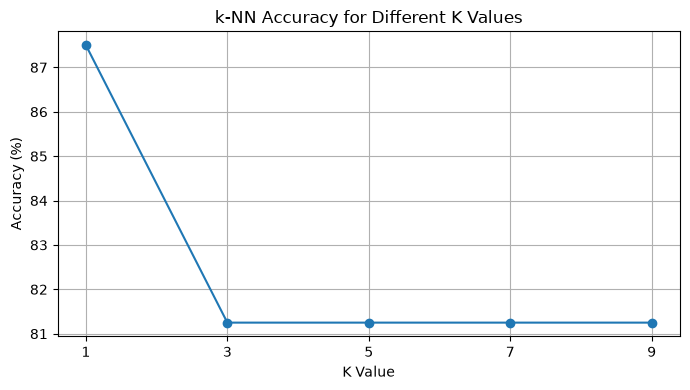

In [6]:
k_values = [1, 3, 5, 7, 9]
accuracies = []

for value in k_values:
    predicted = knn_predict(
        X_train, y_train, X_test, k=value
    )

    score = np.mean(predicted == y_test) * 100
    accuracies.append(score)

    print("K =", value, "| Accuracy =", round(score, 2), "%")

plt.figure(figsize=(7, 4))
plt.plot(k_values, accuracies, marker="o")
plt.xlabel("K Value")
plt.ylabel("Accuracy (%)")
plt.title("k-NN Accuracy for Different K Values")
plt.xticks(k_values)
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
best_index = np.argmax(accuracies)

print("Conclusion")
print("The k-NN classifier was implemented from scratch.")
print("Pairwise Euclidean distances were calculated manually.")
print("Partial sorting was used to find nearest neighbors efficiently.")
print("Voting ties were resolved using total neighbor distance.")
print("Best K value:", k_values[best_index])
print("Best accuracy:", round(accuracies[best_index], 2), "%")

Conclusion
The k-NN classifier was implemented from scratch.
Pairwise Euclidean distances were calculated manually.
Partial sorting was used to find nearest neighbors efficiently.
Voting ties were resolved using total neighbor distance.
Best K value: 1
Best accuracy: 87.5 %
